In [24]:

import json
import numpy as np
import pandas as pd
from pathlib import Path

# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

GOLD_PATH = "../data/test_split.json"

MODELOS = {
    # BASE
    "DeBERTa Base": "13-06/deberta_base.json",
    "ELECTRA Base": "13-06/electra_base.json",
    "Michi Base": "13-06/michi_base.json",
    "Micro Base": "13-06/micro_base.json",
    "Ming Base": "13-06/ming_base.json",

    # CRF
    "DeBERTa CRF": "13-06/deberta_crf.json",
    "ELECTRA CRF": "13-06/electra_crf.json",
    "Michi CRF": "13-06/michi_crf.json",
    "Micro CRF": "13-06/micro_crf.json",
    "Ming CRF": "13-06/ming_crf.json",

    # BiLSTM
    "DeBERTa BiLSTM": "13-06/deberta_lstm.json",
    "ELECTRA BiLSTM": "13-06/electra_lstm.json",
    "Michi BiLSTM": "13-06/michi_lstm.json",
    "Micro BiLSTM": "13-06/micro_lstm.json",
    "Ming BiLSTM": "13-06/ming_lstm.json",

    "gliner": "../../../inferencia_test.json",
    "gliner2": "../../../inferencia_test2.json"
}

B = 1000
SEED = 42

# Si quieres comparar todos los modelos entre sí:
COMPARAR_TODOS = False

# 1. Mismo encoder, distintas arquitecturas
# Compara Base, CRF y BiLSTM para cada encoder.

COMPARACIONES_ARQUITECTURAS = [
    ("DeBERTa Base", "DeBERTa CRF", "DeBERTa BiLSTM"),
    ("ELECTRA Base", "ELECTRA CRF", "ELECTRA BiLSTM"),
    ("Michi Base", "Michi CRF", "Michi BiLSTM"),
    ("Micro Base", "Micro CRF", "Micro BiLSTM"),
    ("Ming Base", "Ming CRF", "Ming BiLSTM"),
]

# 2. Misma arquitectura, distintos encoders
# Compara los cinco encoders dentro de cada arquitectura.

COMPARACIONES_ENCODERS = [
    (
        "DeBERTa Base",
        "ELECTRA Base",
        "Michi Base",
        "Micro Base",
        "Ming Base",
        "gliner2"
    ),
    (
        "DeBERTa CRF",
        "ELECTRA CRF",
        "Michi CRF",
        "Micro CRF",
        "Ming CRF",
        "gliner2"
    ),
    (
        "DeBERTa BiLSTM",
        "ELECTRA BiLSTM",
        "Michi BiLSTM",
        "Micro BiLSTM",
        "Ming BiLSTM",
        "gliner2"
    ),
]

# Combinar ambos tipos de comparaciones
COMPARACIONES = (
    COMPARACIONES_ARQUITECTURAS
    + COMPARACIONES_ENCODERS
)

# ============================================================
# 2. CARGAR JSON
# ============================================================

def cargar_json(ruta):
    with open(ruta, "r", encoding="utf-8") as f:
        return json.load(f)


gold = cargar_json(GOLD_PATH)

predicciones = {
    nombre: cargar_json(ruta)
    for nombre, ruta in MODELOS.items()
}

# Los documentos se obtienen SIEMPRE del gold.
pmids = sorted(gold.keys())
n_docs = len(pmids)

print(f"Documentos de test: {n_docs}")

# Comprobar que ningún modelo contiene documentos inesperados.
for nombre, pred in predicciones.items():
    extras = set(pred) - set(gold)
    faltantes = set(gold) - set(pred)

    if extras or faltantes:
        raise ValueError(
            f"{nombre}: {len(extras)} documentos extra y "
            f"{len(faltantes)} documentos faltantes."
        )

# ============================================================
# 3. CONVERTIR ENTIDADES A TUPLAS
# ============================================================

def obtener_tuplas(documento):
    return {
        (
            entidad["start_idx"],
            entidad["end_idx"],
            entidad["label"],
            entidad["location"],
        )
        for entidad in documento["entities"]
    }


gold_sets = [
    obtener_tuplas(gold[pmid])
    for pmid in pmids
]

pred_sets = {
    nombre: [
        obtener_tuplas(pred[pmid])
        for pmid in pmids
    ]
    for nombre, pred in predicciones.items()
}

# Categorías presentes en el conjunto gold.
# Se mantienen fijas en todos los remuestreos.
CLASES = sorted({
    entidad[2]
    for documento in gold_sets
    for entidad in documento
})

print(f"Categorías: {len(CLASES)}")
print(CLASES)

# ============================================================
# 4. CONTAR TP, FP Y FN POR DOCUMENTO Y CATEGORÍA
# ============================================================

def contar_por_documento(gold_docs, pred_docs, clases):
    n = len(gold_docs)
    k = len(clases)

    tp = np.zeros((n, k), dtype=np.int64)
    fp = np.zeros((n, k), dtype=np.int64)
    fn = np.zeros((n, k), dtype=np.int64)

    clase_a_indice = {
        clase: i for i, clase in enumerate(clases)
    }

    for i, (true_set, pred_set) in enumerate(
        zip(gold_docs, pred_docs)
    ):
        correctas = true_set & pred_set
        falsas_positivas = pred_set - true_set
        falsas_negativas = true_set - pred_set

        for entidad in correctas:
            tp[i, clase_a_indice[entidad[2]]] += 1

        for entidad in falsas_positivas:
            tp_clase = entidad[2]
            if tp_clase in clase_a_indice:
                fp[i, clase_a_indice[tp_clase]] += 1

        for entidad in falsas_negativas:
            fn[i, clase_a_indice[entidad[2]]] += 1

    return tp, fp, fn


# Incluir también categorías predichas que no estén en gold.
# Esto garantiza que los FP se contabilicen correctamente.
CLASES = sorted(
    set(CLASES)
    | {
        entidad[2]
        for documentos in pred_sets.values()
        for documento in documentos
        for entidad in documento
    }
)

# Para Macro-F1, utilizar únicamente las categorías oficiales
# de GutBrainIE si tu evaluación original hace eso.
# Puedes sustituir CLASES por una lista explícita de 13 etiquetas.

conteos = {
    nombre: contar_por_documento(
        gold_sets, docs, CLASES
    )
    for nombre, docs in pred_sets.items()
}

# ============================================================
# 5. CALCULAR MICRO-F1 Y MACRO-F1
# ============================================================

def calcular_metricas(tp, fp, fn):
    """
    tp, fp y fn son vectores con los conteos por categoría.
    """

    tp_total = tp.sum()
    fp_total = fp.sum()
    fn_total = fn.sum()

    denominador_micro = (
        2 * tp_total + fp_total + fn_total
    )

    micro = (
        2 * tp_total / denominador_micro
        if denominador_micro > 0 else 0.0
    )

    denominadores = 2 * tp + fp + fn

    f1_por_clase = np.divide(
        2 * tp,
        denominadores,
        out=np.zeros_like(tp, dtype=float),
        where=denominadores > 0,
    )

    macro = f1_por_clase.mean()

    return micro, macro


# ============================================================
# 6. GENERAR UNA ÚNICA MATRIZ DE BOOTSTRAP
# ============================================================

rng = np.random.default_rng(SEED)

bootstrap_indices = rng.integers(
    low=0,
    high=n_docs,
    size=(B, n_docs),
)

# Todos los modelos utilizan EXACTAMENTE esta matriz.
# Los documentos repetidos se contabilizan varias veces.

# ============================================================
# 7. CALCULAR IC 95 % PARA CADA MODELO
# ============================================================

resultados = []
distribuciones = {}

for nombre, (tp, fp, fn) in conteos.items():

    micro_original, macro_original = calcular_metricas(
        tp.sum(axis=0),
        fp.sum(axis=0),
        fn.sum(axis=0),
    )

    micro_scores = np.zeros(B)
    macro_scores = np.zeros(B)

    for b, indices in enumerate(bootstrap_indices):

        tp_b = tp[indices].sum(axis=0)
        fp_b = fp[indices].sum(axis=0)
        fn_b = fn[indices].sum(axis=0)

        micro_scores[b], macro_scores[b] = (
            calcular_metricas(tp_b, fp_b, fn_b)
        )

    micro_lo, micro_hi = np.percentile(
        micro_scores, [2.5, 97.5]
    )

    macro_lo, macro_hi = np.percentile(
        macro_scores, [2.5, 97.5]
    )

    distribuciones[nombre] = {
        "micro": micro_scores,
        "macro": macro_scores,
    }

    resultados.append({
        "Modelo": nombre,
        "Micro-F1": micro_original,
        "IC Micro inferior": micro_lo,
        "IC Micro superior": micro_hi,
        "Macro-F1": macro_original,
        "IC Macro inferior": macro_lo,
        "IC Macro superior": macro_hi,
        "Micro-F1 (IC 95 %)": (
            f"{micro_original:.4f} "
            f"[{micro_lo:.4f}, {micro_hi:.4f}]"
        ),
        "Macro-F1 (IC 95 %)": (
            f"{macro_original:.4f} "
            f"[{macro_lo:.4f}, {macro_hi:.4f}]"
        ),
    })


df_resultados = pd.DataFrame(resultados)

print("\nRESULTADOS CON INTERVALOS DE CONFIANZA")
print(
    df_resultados[
        [
            "Modelo",
            "Micro-F1 (IC 95 %)",
            "Macro-F1 (IC 95 %)",
        ]
    ].to_string(index=False)
)

# ============================================================
# 8. BOOTSTRAP PAREADO ENTRE MODELOS
# ============================================================

from itertools import combinations

if COMPARAR_TODOS:
    pares = list(combinations(MODELOS.keys(), 2))
else:
    pares = []

    for grupo in COMPARACIONES:
        pares.extend(combinations(grupo, 2))
print(pares)
print(modelo_a)

for modelo_a, modelo_b in pares:

    micro_a = distribuciones[modelo_a]["micro"]
    micro_b = distribuciones[modelo_b]["micro"]

    macro_a = distribuciones[modelo_a]["macro"]
    macro_b = distribuciones[modelo_b]["macro"]

    diferencias_micro = micro_a - micro_b
    diferencias_macro = macro_a - macro_b

    micro_lo, micro_hi = np.percentile(
        diferencias_micro, [2.5, 97.5]
    )

    macro_lo, macro_hi = np.percentile(
        diferencias_macro, [2.5, 97.5]
    )

    fila_a = df_resultados.set_index("Modelo").loc[modelo_a]
    fila_b = df_resultados.set_index("Modelo").loc[modelo_b]

    delta_micro = (
        fila_a["Micro-F1"] - fila_b["Micro-F1"]
    )

    delta_macro = (
        fila_a["Macro-F1"] - fila_b["Macro-F1"]
    )

    resultados_comparaciones.append({
        "Modelo A": modelo_a,
        "Modelo B": modelo_b,
        "Diferencia Micro-F1": delta_micro,
        "IC Micro inferior": micro_lo,
        "IC Micro superior": micro_hi,
        "Diferencia Macro-F1": delta_macro,
        "IC Macro inferior": macro_lo,
        "IC Macro superior": macro_hi,
        "Micro significativo 95 %": (
            micro_lo > 0 or micro_hi < 0
        ),
        "Macro significativo 95 %": (
            macro_lo > 0 or macro_hi < 0
        ),
    })


df_comparaciones = pd.DataFrame(
    resultados_comparaciones
)

print("\nCOMPARACIONES PAREADAS")
print(df_comparaciones.to_string(index=False))

# ============================================================
# 9. GUARDAR RESULTADOS
# ============================================================

df_resultados.to_csv(
    "resultados_bootstrap_ner.csv",
    index=False,
    encoding="utf-8-sig",
)

df_comparaciones.to_csv(
    "comparaciones_pareadas_ner2.csv",
    index=False,
    encoding="utf-8-sig",
)

# Guardar índices para reproducir exactamente los remuestreos.
np.save(
    "bootstrap_indices_ner.npy",
    bootstrap_indices,
)

print("\nArchivos guardados correctamente.")


Documentos de test: 40
Categorías: 13
['DDF', 'anatomical location', 'animal', 'bacteria', 'biomedical technique', 'chemical', 'dietary supplement', 'drug', 'food', 'gene', 'human', 'microbiome', 'statistical technique']

RESULTADOS CON INTERVALOS DE CONFIANZA
        Modelo      Micro-F1 (IC 95 %)      Macro-F1 (IC 95 %)
  DeBERTa Base 0.8056 [0.7667, 0.8439] 0.7255 [0.6650, 0.7838]
  ELECTRA Base 0.8083 [0.7730, 0.8446] 0.7178 [0.6592, 0.7790]
    Michi Base 0.8112 [0.7744, 0.8457] 0.7368 [0.6700, 0.7766]
    Micro Base 0.8191 [0.7781, 0.8573] 0.7521 [0.6881, 0.8046]
     Ming Base 0.8114 [0.7754, 0.8452] 0.7424 [0.6849, 0.7967]
   DeBERTa CRF 0.8047 [0.7692, 0.8408] 0.7094 [0.6450, 0.7576]
   ELECTRA CRF 0.8066 [0.7689, 0.8413] 0.7130 [0.6518, 0.7656]
     Michi CRF 0.8164 [0.7773, 0.8530] 0.7591 [0.6954, 0.8182]
     Micro CRF 0.8127 [0.7743, 0.8483] 0.7504 [0.6925, 0.7961]
      Ming CRF 0.7968 [0.7606, 0.8341] 0.7096 [0.6506, 0.7556]
DeBERTa BiLSTM 0.7930 [0.7592, 0.8279] 0.7117 

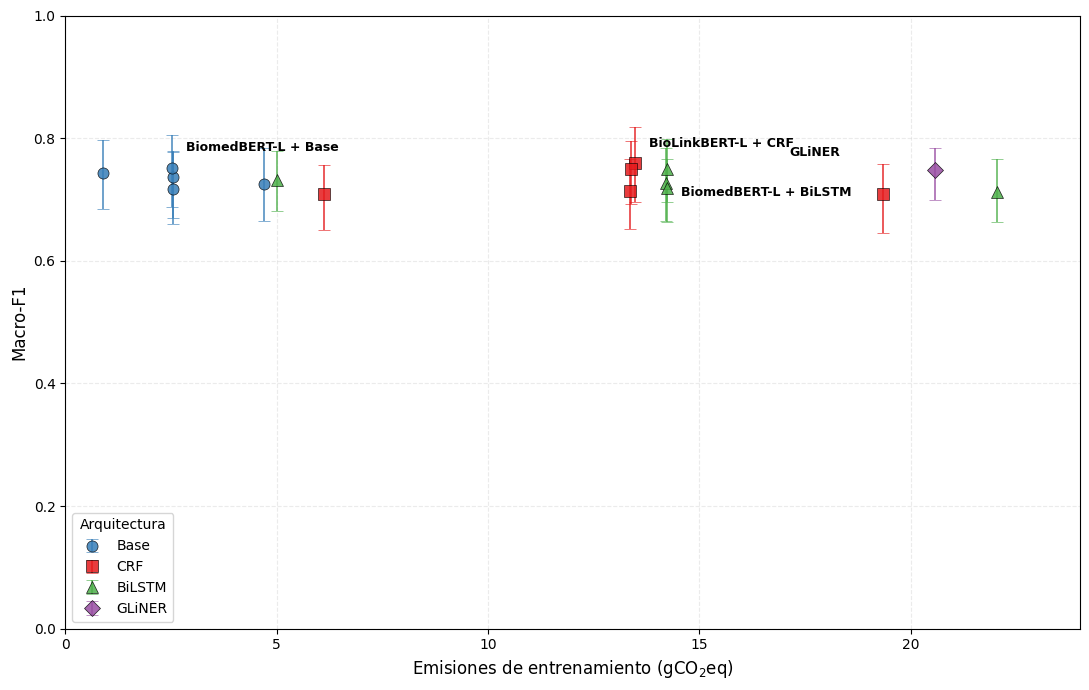

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================================
# 1. DATOS
# ==========================================================

# Modelo, Arquitectura, Macro-F1, IC inferior, IC superior,
# emisiones de entrenamiento (gCO2eq)

datos = [
    ("DeBERTa-L", "Base", 0.7255, 0.6650, 0.7838, 4.698),
    ("BioLinkBERT-L", "Base", 0.7368, 0.6700, 0.7766, 2.536),
    ("BiomedBERT-B", "Base", 0.7424, 0.6849, 0.7967, 0.887),
    ("BiomedBERT-L", "Base", 0.7521, 0.6881, 0.8046, 2.535),
    ("BioELECTRA-L", "Base", 0.7178, 0.6592, 0.7790, 2.557),

    ("DeBERTa-L", "CRF", 0.7094, 0.6450, 0.7576, 19.346),
    ("BioLinkBERT-L", "CRF", 0.7591, 0.6954, 0.8182, 13.483),
    ("BiomedBERT-B", "CRF", 0.7096, 0.6506, 0.7556, 6.125),
    ("BiomedBERT-L", "CRF", 0.7504, 0.6925, 0.7961, 13.381),
    ("BioELECTRA-L", "CRF", 0.7130, 0.6518, 0.7656, 13.359),

    ("DeBERTa-L", "BiLSTM", 0.7117, 0.6629, 0.7654, 22.035),
    ("BioLinkBERT-L", "BiLSTM", 0.7269, 0.6654, 0.7836, 14.217),
    ("BiomedBERT-B", "BiLSTM", 0.7318, 0.6811, 0.7796, 5.009),
    ("BiomedBERT-L", "BiLSTM", 0.7503, 0.6960, 0.7982, 14.224),
    ("BioELECTRA-L", "BiLSTM", 0.7188, 0.6640, 0.7663, 14.242),

    ("GLiNER (NuNerZero)", "GLiNER",
     0.7479, 0.6992, 0.7839, 20.578),
]

df = pd.DataFrame(
    datos,
    columns=[
        "Modelo", "Arquitectura", "Macro-F1",
        "IC_inf", "IC_sup", "CO2"
    ]
)

# ==========================================================
# 2. CONFIGURACIÓN
# ==========================================================

colores = {
    "Base": "#377eb8",
    "CRF": "#e41a1c",
    "BiLSTM": "#4daf4a",
    "GLiNER": "#984ea3"
}

marcadores = {
    "Base": "o",
    "CRF": "s",
    "BiLSTM": "^",
    "GLiNER": "D"
}

salida = Path("graficas_emisiones")
salida.mkdir(exist_ok=True)

# ==========================================================
# 3. GRÁFICA
# ==========================================================

fig, ax = plt.subplots(figsize=(11, 7))

for arquitectura in ["Base", "CRF", "BiLSTM", "GLiNER"]:

    subset = df[df["Arquitectura"] == arquitectura]

    # Barras de error asimétricas:
    # distancia desde F1 al límite inferior y superior
    errores = np.vstack([
        subset["Macro-F1"] - subset["IC_inf"],
        subset["IC_sup"] - subset["Macro-F1"]
    ])

    ax.errorbar(
        subset["CO2"],
        subset["Macro-F1"],
        yerr=errores,
        fmt=marcadores[arquitectura],
        color=colores[arquitectura],
        markersize=8,
        markeredgecolor="black",
        markeredgewidth=0.5,
        elinewidth=1.2,
        capsize=4,
        capthick=1.2,
        alpha=0.85,
        linestyle="none",
        label=arquitectura,
        zorder=3
    )

# ==========================================================
# 4. ETIQUETAS DE MODELOS DESTACADOS
# ==========================================================

# Se etiquetan únicamente los modelos más relevantes
# para evitar saturar la gráfica.

destacados = [
    ("BiomedBERT-L", "Base"),
    ("BioLinkBERT-L", "CRF"),
    ("BiomedBERT-L", "BiLSTM"),
    ("GLiNER (NuNerZero)", "GLiNER")
]

desplazamientos = {
    ("BiomedBERT-L", "Base"): (10, 12),
    ("BioLinkBERT-L", "CRF"): (10, 12),
    ("BiomedBERT-L", "BiLSTM"): (10, -20),
    ("GLiNER (NuNerZero)", "GLiNER"): (-105, 10)
}

for modelo, arquitectura in destacados:

    fila = df[
        (df["Modelo"] == modelo) &
        (df["Arquitectura"] == arquitectura)
    ].iloc[0]

    etiqueta = (
        "GLiNER"
        if arquitectura == "GLiNER"
        else f"{modelo} + {arquitectura}"
    )

    ax.annotate(
        etiqueta,
        (fila["CO2"], fila["Macro-F1"]),
        xytext=desplazamientos[(modelo, arquitectura)],
        textcoords="offset points",
        fontsize=9,
        fontweight="bold"
    )

# ==========================================================
# 5. FORMATO
# ==========================================================

ax.set_xlabel(
    "Emisiones de entrenamiento (gCO$_2$eq)",
    fontsize=12
)

ax.set_ylabel("Macro-F1", fontsize=12)

ax.set_xlim(0, 24)
ax.set_ylim(0,1)


ax.grid(
    True,
    linestyle="--",
    alpha=0.25
)

ax.legend(
    title="Arquitectura",
    loc="lower left",
    frameon=True
)

plt.tight_layout()

# ==========================================================
# 6. EXPORTACIÓN
# ==========================================================

fig.savefig(
    salida / "macro_f1_co2_ic95.pdf",
    bbox_inches="tight"
)

fig.savefig(
    salida / "macro_f1_co2_ic95.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)
